# Alquiler — 02 Limpieza y preparación (en 3 pasos)

**Paso 1 «encontrar»** (solo diagnóstico, no modifica datos) →
**Paso 2 «refregar»** (tipos, duplicados, inválidos, joins, faltantes,
atípicos, fuga y split) → **Paso 3 «enjuagar»** (repetir el Paso 1 sobre lo
limpio, con asserts).

Regla de frontera: las reglas de negocio se aplican sobre las 20.000 filas
antes de dividir; todo parámetro aprendido (mediana, umbrales IQR, one-hot)
se ajusta solo en train (16.000) y se aplica a test (4.000).

Correr con el kernel **(.venv)**.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder

DATA_DIR = Path("..") / "data"
OUT_DIR = DATA_DIR / "processed"
TARGET = "monthly_rent_rub"
SEED = 42
pd.set_option("display.max_columns", 100)

## Paso 1 — «Encontrar la suciedad» (solo diagnóstico)

Se mide, no se toca. El crudo se lee una vez; todo cambio ocurre en el Paso 2.

In [2]:
rentals = pd.read_csv(DATA_DIR / "rentals.csv")
assert rentals.shape == (20000, 22), f"forma inesperada: {rentals.shape}"
print(f"{len(rentals):,} filas x {rentals.shape[1]} columnas | nulos totales: {int(rentals.isna().sum().sum())}")

20,000 filas x 22 columnas | nulos totales: 0


In [3]:
# Diagnostico puro: tabla problema -> afectados -> decision (nada se modifica)
diag = [{"problema": "valores vacios (nulos)", "afectados": int(rentals.isna().sum().sum()),
         "decision": "sin huecos que imputar (Paso 2, faltantes)"}]
for c in [TARGET, "total_area", "metro_distance_min", "to_center_km"]:
    diag.append({"problema": f"distribucion sesgada: {c} (skew={stats.skew(rentals[c]):.2f})",
                 "afectados": len(rentals),
                 "decision": "target a log en Paso 2; formas se eligen al preparar variables"})
fecha = pd.to_datetime(rentals["date_posted"])
diag += [
    {"problema": "floor > total_floors", "afectados": int((rentals["floor"] > rentals["total_floors"]).sum()),
     "decision": "regla de negocio en Paso 2"},
    {"problema": "publicado antes del building_year", "afectados": int((fecha.dt.year < rentals["building_year"]).sum()),
     "decision": "marcar con flag_invalido y conservar"},
    {"problema": "alquiler <= 0 o total_area <= 0",
     "afectados": int(((rentals[TARGET] <= 0) | (rentals["total_area"] <= 0)).sum()),
     "decision": "regla de negocio en Paso 2"},
    {"problema": "rent_per_sqm deriva del target (alquiler/superficie)",
     "afectados": int(((rentals["rent_per_sqm"] - rentals[TARGET] / rentals["total_area"]).abs() <= 1).sum()),
     "decision": "fuga: sale del dataset limpio"},
]
case_cols = rentals.select_dtypes(include=["object", "str"]).columns
n_case = sum(rentals[c].astype(str).nunique()
             != rentals[c].astype(str).str.strip().str.lower().nunique() for c in case_cols)
diag.append({"problema": "strings que solo difieren por case/espacios", "afectados": int(n_case),
             "decision": "normalizar en Paso 2 si fuera > 0; se re-verifica en Paso 3"})
for c in [TARGET, "metro_distance_min"]:
    x = rentals[c]
    lo, hi = x.quantile(0.25) - 1.5 * stats.iqr(x), x.quantile(0.75) + 1.5 * stats.iqr(x)
    diag.append({"problema": f"cola atipica exploratoria en {c}", "afectados": int(((x < lo) | (x > hi)).sum()),
                 "decision": "conservar; flags IQR de train en Paso 2"})
tabla_diag = pd.DataFrame(diag)
display(tabla_diag)
print(f"{len(tabla_diag)} problemas relevados; datos sin modificar.")

,problema,afectados,decision
0,valores vacios (nulos),0,"sin huecos que imputar (Paso 2, faltantes)"
1,distribucion sesgada: monthly_rent_rub (skew=1...,20000,target a log en Paso 2; formas se eligen al pr...
2,distribucion sesgada: total_area (skew=0.58),20000,target a log en Paso 2; formas se eligen al pr...
3,distribucion sesgada: metro_distance_min (skew...,20000,target a log en Paso 2; formas se eligen al pr...
4,distribucion sesgada: to_center_km (skew=2.12),20000,target a log en Paso 2; formas se eligen al pr...
5,floor > total_floors,0,regla de negocio en Paso 2
6,publicado antes del building_year,339,marcar con flag_invalido y conservar
7,alquiler <= 0 o total_area <= 0,0,regla de negocio en Paso 2
8,rent_per_sqm deriva del target (alquiler/super...,17771,fuga: sale del dataset limpio
9,strings que solo difieren por case/espacios,0,normalizar en Paso 2 si fuera > 0; se re-verif...


12 problemas relevados; datos sin modificar.


### Duplicados

Un aviso republicado (mismo inmueble, otra fecha) es legítimo; una fila
idéntica en todo o un `id` repetido es error de carga. Se chequean 4 variantes:

In [4]:
dup = pd.Series({
    "exactos (todas las columnas)": int(rentals.duplicated().sum()),
    "sin id (mismo aviso, otro id)": int(rentals.duplicated(subset=[c for c in rentals.columns if c != "id"]).sum()),
    "id repetido": int(rentals.duplicated(subset=["id"]).sum()),
    "clave de negocio": int(rentals.duplicated(subset=["district", "total_area", "rooms", TARGET, "date_posted"]).sum()),
})
display(dup.rename("filas").to_frame())
assert (dup == 0).all()
print("Decision: 0 duplicados en las 4 variantes -> no se elimina ninguna fila.")

,filas
exactos (todas las columnas),0
"sin id (mismo aviso, otro id)",0
id repetido,0
clave de negocio,0


Decision: 0 duplicados en las 4 variantes -> no se elimina ninguna fila.


## Paso 2 — «Refregar» (aplicar las decisiones)

### Tipos y target en log

`date_posted` se parsea a fecha y se deriva `year_month` conservando la
original; booleanos a 0/1; categóricas a `category` (`rooms` incluida: no es
continua). La coerción a número de cada texto se reporta solo como auditoría:
únicamente se convertiría una columna si casi todo su contenido fuera número.

,columna,exito_coercion
0,id,0.0
1,date_posted,0.0
2,district,0.0
3,okrug,0.0
4,building_type,0.0
5,renovation,0.0
6,metro_station,0.0
7,metro_line,0.0


exito < 0,85 en todas -> ninguna es un numero disfrazado; quedan texto/categoria
rango fechas: 2021-01-01 -> 2026-04-29
skew crudo = 1.82 | skew log1p = -0.14


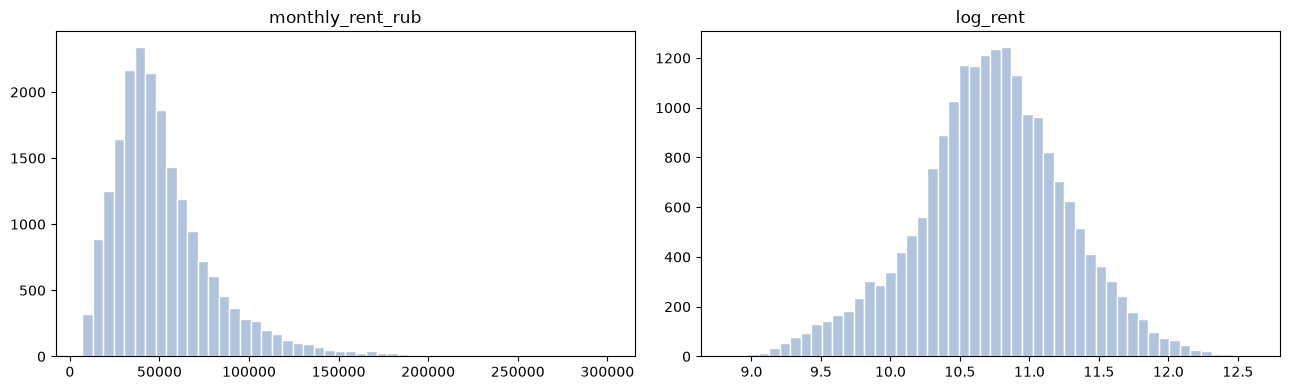

In [5]:
df = rentals.copy()
df["date_posted"] = pd.to_datetime(df["date_posted"], errors="raise")
df["year_month"] = df["date_posted"].dt.strftime("%Y-%m")
for c in ["furnished", "pets_allowed"]:
    df[c] = df[c].astype("int8")
for c in ["district", "okrug", "building_type", "renovation", "metro_station", "metro_line", "rooms"]:
    df[c] = df[c].astype("category")

audit = [{"columna": c,
          "exito_coercion": round(float(pd.to_numeric(rentals[c], errors="coerce").notna().mean()), 3)}
         for c in case_cols]
display(pd.DataFrame(audit))
print("exito < 0,85 en todas -> ninguna es un numero disfrazado; quedan texto/categoria")
print("rango fechas:", df["date_posted"].min().date(), "->", df["date_posted"].max().date())

# Target en log (decision de la exploracion): se conserva el crudo y se agrega log_rent.
df["log_rent"] = np.log1p(df[TARGET])
print(f"skew crudo = {stats.skew(df[TARGET]):.2f} | skew log1p = {stats.skew(df['log_rent']):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col in zip(axes, [TARGET, "log_rent"]):
    ax.hist(df[col], bins=50, color="lightsteelblue", edgecolor="white")
    ax.set_title(col)
plt.tight_layout(); plt.show()

### Columnas innecesarias: justificación de negocio antes de quitar

El objetivo es **predecir el precio de alquiler**; una columna sale solo si
(1) no puede influir legítimamente en ese precio, o (2) influye porque *deriva*
del propio precio (fuga). La verificación es anterior a la quita:

| Columna | Verificación | Decisión |
|---|---|---|
| `id` | identificador arbitrario; sin relación con el precio | queda solo como trazabilidad; nunca predictor |
| `rent_per_sqm` | es el alquiler dividido por la superficie (chequeo exacto más abajo); r = 0,89 con el target | fuera del dataset limpio por fuga |
| `rental_price_per_sqm_monthly` (del join) | agregado distrital del propio alquiler; r = 0,78 con `log_rent` | se conserva marcada en esta limpieza; sale de los artefactos al preparar las variables |
| `lat` / `lon` y coordenadas de la estación | redundantes con `to_center_km` (r ≈ −0,71 en la exploración) | se conservan en el limpio; no entran a la matriz de variables |

Ninguna otra columna se elimina acá: el resto puede influir en el precio y
su aporte lo juzga el modelo, no la limpieza.

### Valores inválidos: reglas de negocio (pre-split)

Las reglas no dependen de la distribución (un piso no puede superar los pisos
del edificio), así que van sobre las 20.000 filas. Resultado: 8 de 9 dan 0;
los 339 avisos (1,7 %) publicados antes del `building_year` se **marcan con
`flag_invalido` y se conservan** (puede ser alquiler sobre plano; borrarlos
eliminaría el segmento de edificios nuevos).

In [6]:
anio_pub = df["date_posted"].dt.year
reglas = {
    "floor > total_floors": df["floor"] > df["total_floors"],
    "floor < 1 o total_floors < 1": (df["floor"] < 1) | (df["total_floors"] < 1),
    "total_area <= 0": df["total_area"] <= 0,
    "alquiler <= 0": df[TARGET] <= 0,
    "rooms fuera de 1-4": ~df["rooms"].isin([1, 2, 3, 4]),
    "deposit_months fuera de 0-2": ~df["deposit_months"].isin([0, 1, 2]),
    "building_year implausible o futuro": (df["building_year"] < 1800) | (df["building_year"] > anio_pub),
    "distancias negativas": (df["metro_distance_min"] < 0) | (df["to_center_km"] < 0),
    "lat/lon fuera de Moscu": ~df["lat"].between(55.0, 56.2) | ~df["lon"].between(36.5, 38.0),
}
display(pd.Series({k: int(v.sum()) for k, v in reglas.items()}, name="violaciones").to_frame())
df["flag_invalido"] = np.logical_or.reduce(list(reglas.values()))
print(f"flag_invalido: {int(df['flag_invalido'].sum())} filas marcadas, ninguna excluida")

,violaciones
floor > total_floors,0
floor < 1 o total_floors < 1,0
total_area <= 0,0
alquiler <= 0,0
rooms fuera de 1-4,0
deposit_months fuera de 0-2,0
building_year implausible o futuro,339
distancias negativas,0
lat/lon fuera de Moscu,0


flag_invalido: 339 filas marcadas, ninguna excluida


### Joins reproducidos

Se repiten los joins de contexto con claves únicas verificadas: el resultado
debe conservar 20.000 filas. Las columnas duplicadas por el join se eliminan
o renombran una sola vez, acá.

In [7]:
monthly = pd.read_csv(DATA_DIR / "district_prices_monthly.csv")
metro = pd.read_csv(DATA_DIR / "metro_stations.csv")
assert not monthly.duplicated(["district", "year_month"]).any()
assert not metro.duplicated(["station_name"]).any()

n0 = len(df)
enr = df.merge(monthly, on=["district", "year_month"], how="left", suffixes=("", "_distmes"), indicator="m1")
print(f"join mensual: {n0:,} -> {len(enr):,} | match={(enr['m1'] == 'both').mean():.2%}")
enr = enr.drop(columns=["m1"]).merge(metro, left_on="metro_station", right_on="station_name",
                                     how="left", suffixes=("", "_metro"), indicator="m2")
print(f"join metro: match={(enr['m2'] == 'both').mean():.2%}")
enr = enr.drop(columns=["m2"])
assert len(enr) == n0, "el join cambio la cantidad de filas"
assert (enr.groupby("metro_station")["metro_line"].nunique() == 1).all()
assert (enr.groupby("district")["okrug"].nunique() == 1).all()
assert (enr["metro_line"] == enr["line"]).all()
enr = enr.drop(columns=["okrug_distmes", "station_name", "line"]).rename(
    columns={"lat_metro": "station_lat", "lon_metro": "station_lon",
             "to_center_km_metro": "station_to_center_km"})
new_cols = [c for c in enr.columns if c not in df.columns]
print(f"columnas nuevas ({len(new_cols)}): {new_cols}")
df = enr

join mensual: 20,000 -> 20,000 | match=100.00%
join metro: match=100.00%
columnas nuevas (14): ['secondary_price_per_sqm', 'newbuild_price_per_sqm', 'rental_price_per_sqm_monthly', 'secondary_mom_change_pct', 'newbuild_mom_change_pct', 'n_listings_secondary', 'n_listings_newbuild', 'n_listings_rental', 'cbr_key_rate_pct', 'avg_mortgage_rate_pct', 'station_lat', 'station_lon', 'year_opened', 'station_to_center_km']


### Valores faltantes

La base no trae nulos y el join tampoco los introduce: los únicos 129 NaN del
mensual son de `2020-01` (sin mes previo para la variación) y los avisos
empiezan en `2021-01`. Los 3 enfoques posibles quedan declarados:

- **Eliminar filas:** descartado; borraría avisos válidos y sesgaría por distrito.
- **Recodificar** (nivel "sin dato"): no aplica; no falta ninguna categórica.
- **Imputar** (mediana de train): elegido como red de seguridad en el split,
  sin efecto hoy.

In [8]:
print(f"nulos totales tras joins: {int(df.isna().sum().sum())} en {df.shape[1]} columnas")
print("NaN del mensual solo en:",
      sorted(monthly.loc[monthly["secondary_mom_change_pct"].isna(), "year_month"].unique()),
      "| avisos desde:", df["year_month"].min())

nulos totales tras joins: 0 en 39 columnas
NaN del mensual solo en: ['2020-01'] | avisos desde: 2021-01


### Valores atípicos: investigar antes de tocar

Lectura de colas, no filtrado: alquiler q99 ≈ 161k y máximo 300.700 RUB
(mediana 45.800); `metro_distance_min` llega a 966 min. Pueden ser segmento
premium real o errores, y OLS es sensible a ambos. **Decisión:** conservar
todo, sin winsorizar; se marcan con flags IQR de train recién en el split.

In [9]:
cols_out = [TARGET, "total_area", "metro_distance_min", "to_center_km"]
q = df[cols_out].quantile([0.5, 0.99, 0.999, 1.0]).T.rename(
    columns={0.5: "mediana", 0.99: "q99", 0.999: "q99.9", 1.0: "max"})
display(q.round(1))
for c in cols_out:
    x = df[c]
    lo, hi = x.quantile(0.25) - 1.5 * stats.iqr(x), x.quantile(0.75) + 1.5 * stats.iqr(x)
    print(f"{c}: fuera de IQR exploratorio = {int(((x < lo) | (x > hi)).sum())} "
          f"({((x < lo) | (x > hi)).mean():.1%})  [el umbral util es el de train]")

,mediana,q99,q99.9,max
monthly_rent_rub,45800.0,161102.0,229306.5,300700.0
total_area,53.8,89.2,96.2,104.6
metro_distance_min,103.0,776.0,909.0,966.0
to_center_km,13.2,66.0,68.8,71.1


monthly_rent_rub: fuera de IQR exploratorio = 936 (4.7%)  [el umbral util es el de train]
total_area: fuera de IQR exploratorio = 174 (0.9%)  [el umbral util es el de train]
metro_distance_min: fuera de IQR exploratorio = 1416 (7.1%)  [el umbral util es el de train]
to_center_km: fuera de IQR exploratorio = 1905 (9.5%)  [el umbral util es el de train]


### Identificadores y fuga

`id` queda solo para trazabilidad. `rent_per_sqm` **sale**: es el target
dividido por la superficie. `rental_price_per_sqm_monthly` se conserva
marcada (contexto del distrito, cercano al target). La colinealidad entre
pares (distancias, superficie/ambientes, lat/lon) se resuelve una sola vez
al modelar, no acá.

In [10]:
chk = (df["rent_per_sqm"] - df[TARGET] / df["total_area"]).abs().max()
print(f"max |rent_per_sqm - alquiler/superficie| = {chk:.2f} (redondeo) -> deriva del target")
clean = df.drop(columns=["rent_per_sqm"]).copy()
print(f"clean: {clean.shape[0]:,} filas x {clean.shape[1]} columnas (sin rent_per_sqm)")

max |rent_per_sqm - alquiler/superficie| = 2.09 (redondeo) -> deriva del target
clean: 20,000 filas x 38 columnas (sin rent_per_sqm)


### Split y parámetros aprendidos (solo en train)

Recién acá se divide: 80/20 estratificado por `okrug`, semilla 42. Todo lo
anterior fue regla de negocio; lo que sigue se ajusta solo con train:
imputador de mediana (hoy sin efecto, verificado contra la mediana global),
flags de atípicos con umbrales IQR de train, y one-hot k−1 ajustado en train.

In [11]:
train, test = train_test_split(clean, test_size=0.20, random_state=SEED, stratify=clean["okrug"])
print(f"train {len(train):,} | test {len(test):,} | sin solape de id:",
      train["id"].is_unique and test["id"].is_unique and set(train["id"]).isdisjoint(test["id"]))

num_demo = [TARGET, "total_area", "metro_distance_min"]
imp = SimpleImputer(strategy="median").fit(train[num_demo])
display(pd.DataFrame({"mediana_train (usada)": pd.Series(imp.statistics_, index=num_demo),
                      "mediana_global (prohibida)": clean[num_demo].median()}).round(2))
assert np.allclose(imp.statistics_, train[num_demo].median().to_numpy())
assert not np.allclose(imp.statistics_, clean[num_demo].median().to_numpy())
print("OK: el imputador aprendio de train (hoy sin huecos: no altera valores).")

def iqr_flags(base, ref):
    flags = pd.DataFrame(index=base.index)
    for c in ["total_area", "metro_distance_min", "to_center_km", TARGET]:
        x = ref[c]
        lo = x.quantile(0.25) - 1.5 * stats.iqr(x)
        hi = x.quantile(0.75) + 1.5 * stats.iqr(x)
        flags[f"flag_outlier_{c}"] = ((base[c] < lo) | (base[c] > hi)).astype("int8")
    return flags

train_out = pd.concat([train, iqr_flags(train, train)], axis=1)
test_out = pd.concat([test, iqr_flags(test, train)], axis=1)
print("flags en test (umbrales de train):")
display(test_out[[c for c in test_out if c.startswith("flag_outlier")]].sum().rename("filas").to_frame())

cats_modelo = ["rooms", "building_type", "renovation", "okrug", "metro_line"]
enc = OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False).fit(train[cats_modelo])
print(f"one-hot (k-1) ajustado en train: {enc.transform(train[cats_modelo]).shape[1]} columnas desde {cats_modelo}")

train 16,000 | test 4,000 | sin solape de id: True


,mediana_train (usada),mediana_global (prohibida)
monthly_rent_rub,45900.0,45800.0
total_area,53.8,53.8
metro_distance_min,103.0,103.0


OK: el imputador aprendio de train (hoy sin huecos: no altera valores).
flags en test (umbrales de train):


,filas
flag_outlier_total_area,37
flag_outlier_metro_distance_min,275
flag_outlier_to_center_km,387
flag_outlier_monthly_rent_rub,193


one-hot (k-1) ajustado en train: 32 columnas desde ['rooms', 'building_type', 'renovation', 'okrug', 'metro_line']


## Paso 3 — «Enjuagar y repetir» (re-chequeo sobre lo limpio)

Se repite el Paso 1 sobre `clean` y el par train/test. Todo lo encontrado
tiene que estar resuelto o marcado; si apareciera algo nuevo, se documenta
una segunda vuelta al Paso 2 en vez de corregirlo en silencio.

In [12]:
anio_pub2 = pd.to_datetime(clean["date_posted"]).dt.year
sin_marcar = (((clean["floor"] > clean["total_floors"]) | (clean[TARGET] <= 0)
               | (clean["total_area"] <= 0)) & ~clean["flag_invalido"])
n_case2 = sum(clean[c].astype(str).nunique()
              != clean[c].astype(str).str.strip().str.lower().nunique()
              for c in clean.select_dtypes(include=["object", "str", "category"]).columns)
segunda = pd.DataFrame([
    {"chequeo": "nulos en clean / train / test",
     "resultado": f"{int(clean.isna().sum().sum())} / {int(train_out.isna().sum().sum())} / {int(test_out.isna().sum().sum())}"},
    {"chequeo": "duplicados exactos en clean", "resultado": int(clean.duplicated().sum())},
    {"chequeo": "split sin solape (16.000 / 4.000)",
     "resultado": f"{len(train_out):,} / {len(test_out):,} | solape={len(set(train_out['id']) & set(test_out['id']))}"},
    {"chequeo": "imposibles sin marcar", "resultado": int(sin_marcar.sum())},
    {"chequeo": "flag_invalido conservados (sobre plano)", "resultado": int(clean["flag_invalido"].sum())},
    {"chequeo": "columnas con variantes solo por case/espacios", "resultado": int(n_case2)},
    {"chequeo": "skew de log_rent tras la limpieza", "resultado": round(float(stats.skew(clean["log_rent"])), 2)},
])
display(segunda)
assert int(clean.isna().sum().sum()) == 0 and int(clean.duplicated().sum()) == 0
assert len(train_out) == 16000 and len(test_out) == 4000
assert set(train_out["id"]).isdisjoint(test_out["id"])
assert int(sin_marcar.sum()) == 0 and n_case2 == 0
print("Segunda vuelta: NO requerida; todo resuelto o marcado (excepcion conocida:",
      "flag_invalido por publicacion previa al building_year, conservada a proposito).")

,chequeo,resultado
0,nulos en clean / train / test,0 / 0 / 0
1,duplicados exactos en clean,0
2,split sin solape (16.000 / 4.000),"16,000 / 4,000 | solape=0"
3,imposibles sin marcar,0
4,flag_invalido conservados (sobre plano),339
5,columnas con variantes solo por case/espacios,0
6,skew de log_rent tras la limpieza,-0.14


Segunda vuelta: NO requerida; todo resuelto o marcado (excepcion conocida: flag_invalido por publicacion previa al building_year, conservada a proposito).


## Guardado

Tres artefactos en `data/processed/`: la base limpia pre-split (sin
`rent_per_sqm`) y el par train/test con flags de atípicos de train. Los
crudos de `data/` no se modifican.

In [13]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
clean.to_csv(OUT_DIR / "rentals_clean.csv", index=False)
train_out.to_csv(OUT_DIR / "rentals_train.csv", index=False)
test_out.to_csv(OUT_DIR / "rentals_test.csv", index=False)
for f in ["rentals_clean.csv", "rentals_train.csv", "rentals_test.csv"]:
    d = pd.read_csv(OUT_DIR / f)
    print(f"{f}: {d.shape[0]:,} x {d.shape[1]} | rent_per_sqm presente: {'rent_per_sqm' in d.columns}")

rentals_clean.csv: 20,000 x 38 | rent_per_sqm presente: False
rentals_train.csv: 16,000 x 42 | rent_per_sqm presente: False
rentals_test.csv: 4,000 x 42 | rent_per_sqm presente: False
